In [ ]:
!pip install scikit-learn hmmlearn matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 kB 4.2 MB/s eta 0:00:00


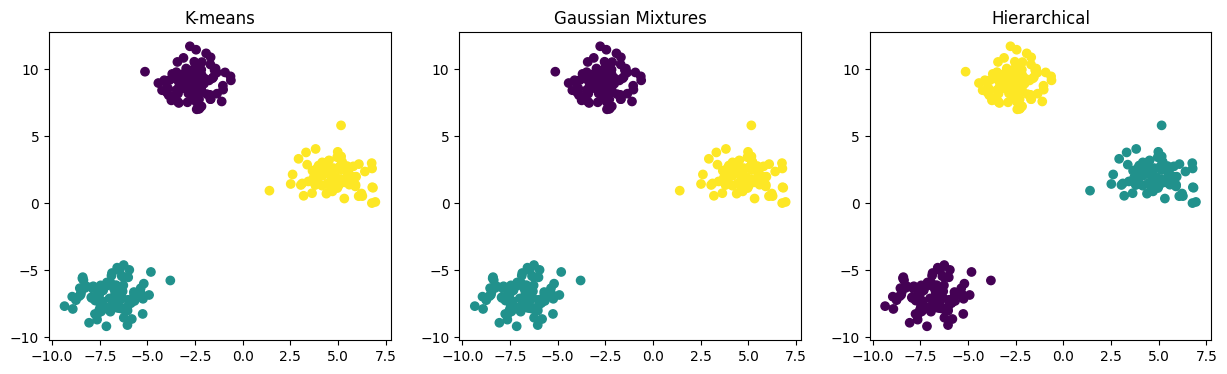

In [ ]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt

# Sample data
X, _ = make_blobs(n_samples=300, centers=3, random_state=42)

# K-means
kmeans = KMeans(n_clusters=3, random_state=42).fit(X)
labels_kmeans = kmeans.labels_

# Gaussian Mixture
gmm = GaussianMixture(n_components=3, random_state=42).fit(X)
labels_gmm = gmm.predict(X)

# Hierarchical Clustering
agglo = AgglomerativeClustering(n_clusters=3).fit(X)
labels_agglo = agglo.labels_

# Plotting
plt.figure(figsize=(15,4))
for i, labels, title in zip(range(1,4), [labels_kmeans, labels_gmm, labels_agglo],
                            ['K-means', 'Gaussian Mixtures', 'Hierarchical']):
    plt.subplot(1,3,i)
    plt.scatter(X[:,0], X[:,1], c=labels)
    plt.title(title)
plt.show()


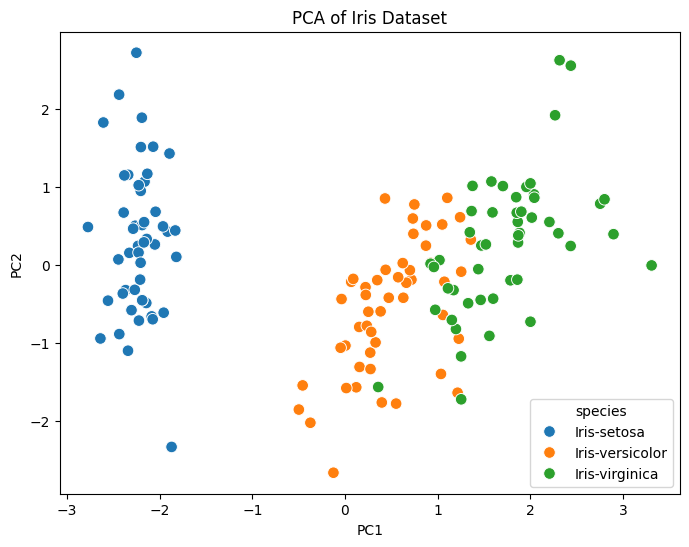

Explained variance ratio per principal component: [0.72770452 0.23030523]


In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"
columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
data = pd.read_csv(url, header=None, names=columns)

X = data.iloc[:, 0:4]
y = data['species']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['species'] = y

plt.figure(figsize=(8,6))
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='species', s=70)
plt.title('PCA of Iris Dataset')
plt.show()

print("Explained variance ratio per principal component:", pca.explained_variance_ratio_)


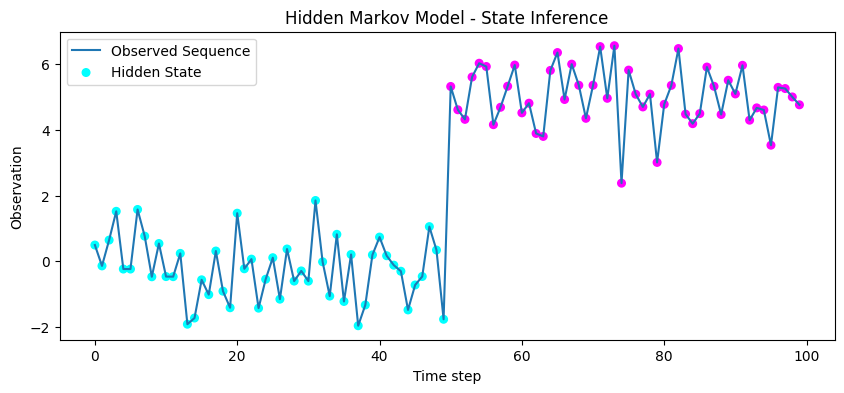

Means of each hidden state: [-0.2254739   5.01778087]
Predicted hidden states: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


In [ ]:
import numpy as np
from hmmlearn import hmm
import matplotlib.pyplot as plt

np.random.seed(42)
obs1 = np.random.normal(loc=0, scale=1, size=50)
obs2 = np.random.normal(loc=5, scale=1, size=50)
X = np.concatenate([obs1, obs2]).reshape(-1, 1)

model = hmm.GaussianHMM(n_components=2, covariance_type='diag', n_iter=100, random_state=42)
model.fit(X)

hidden_states = model.predict(X)

plt.figure(figsize=(10,4))
plt.plot(X, label='Observed Sequence')
plt.scatter(range(len(X)), X.squeeze(), c=hidden_states, cmap='cool', label='Hidden State', s=30)
plt.title('Hidden Markov Model - State Inference')
plt.xlabel('Time step')
plt.ylabel('Observation')
plt.legend()
plt.show()

print('Means of each hidden state:', model.means_.ravel())
print('Predicted hidden states:', hidden_states)



              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

Accuracy: 1.0


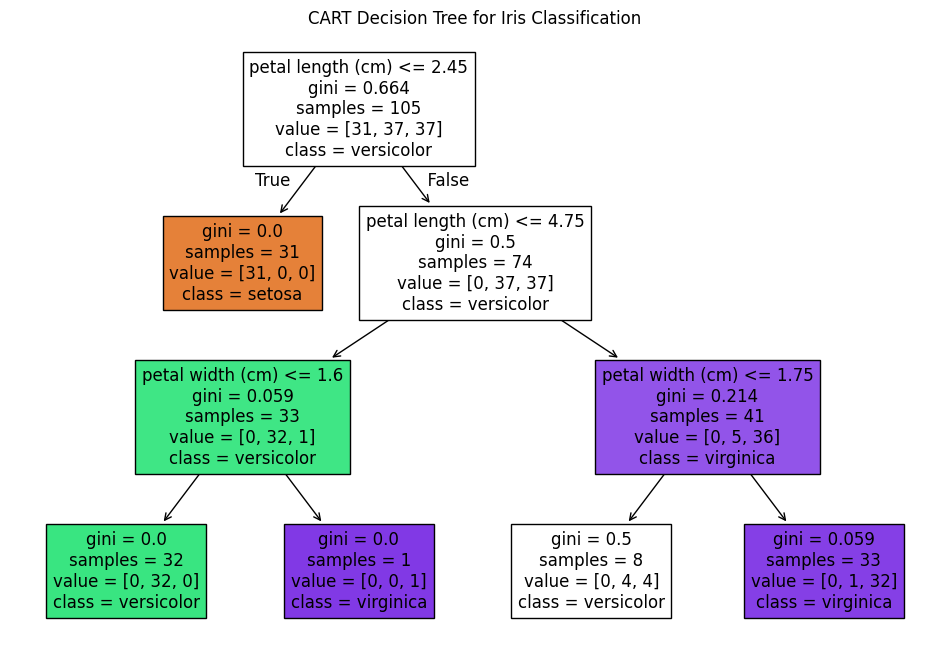

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, accuracy_score
import matplotlib.pyplot as plt

X, y = load_iris(return_X_y=True)
feature_names = load_iris().feature_names

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

clf = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))

plt.figure(figsize=(12,8))
plot_tree(clf, feature_names=feature_names, class_names=load_iris().target_names, filled=True)
plt.title('CART Decision Tree for Iris Classification')
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

rf = RandomForestClassifier(n_estimators=100, random_state=42)
gb = GradientBoostingClassifier(n_estimators=100, random_state=42)

ensemble = VotingClassifier(estimators=[('rf', rf), ('gb', gb)], voting='soft')

ensemble.fit(X_train, y_train)

y_pred = ensemble.predict(X_test)
print("Accuracy of Voting Ensemble:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy of Voting Ensemble: 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

